In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import sys, sklearn, xgboost, imblearn, shap, pandas, numpy, joblib
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgboost.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("shap:", shap.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("joblib:", joblib.__version__)

Python: 3.13.18
scikit-learn: 1.6.1
xgboost: 3.4.1
imbalanced-learn: 0.14.2
shap: 0.54.1
pandas: 2.2.3
numpy: 2.4.6
joblib: 1.6.0


In [ ]:


import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

warnings.filterwarnings("ignore")

BASE_DIR = "/content/drive/MyDrive/ChurnGuard"

folders = [
    "data",
    "models",
    "results",
    "plots",
    "checkpoints",
    "app"
]

for folder in folders:
    os.makedirs(
        os.path.join(BASE_DIR, folder),
        exist_ok=True
    )
print("Project directory:", BASE_DIR)

print("\nProject folders:")
for folder in folders:
    print("CREATE", folder)

Project directory: /content/drive/MyDrive/ChurnGuard

Project folders:
CREATE data
CREATE models
CREATE results
CREATE plots
CREATE checkpoints
CREATE app


 UPLOAD & SAVE ORIGINAL DATASET

In [ ]:

RAW_PATH = os.path.join(BASE_DIR, "data", "raw_telco.csv")

if os.path.exists(RAW_PATH):
    print("Path:", RAW_PATH)
else:
    from google.colab import files

    uploaded = files.upload()

    csv_files = [
        name for name in uploaded.keys()
        if name.lower().endswith(".csv")
    ]

    if len(csv_files) != 1:
        raise ValueError(" upload CSV dataset.")

    shutil.copy(csv_files[0], RAW_PATH)
    print("Dataset uploaded successfully!")
    print("Dataset saved at:", RAW_PATH)

df = pd.read_csv(RAW_PATH)
print("Shape:", df.shape)

Path: /content/drive/MyDrive/ChurnGuard/data/raw_telco.csv
Shape: (7043, 21)


DATASET  INSPECTION

In [ ]:


df = pd.read_csv(RAW_PATH)

print("_" * 35)
print("CHURNGUARD DATASET INFORMATION")
print("_" * 35)

print("\n1. Dataset Shape:")
print(df.shape)

print("\n2. First 5 Records:")
display(df.head())

print("\n3. Column Names:")
print(df.columns.tolist())

print("\n4. Data Types:")
print(df.dtypes)

print("\n5. Missing Values:")
print(df.isnull().sum())

print("\n6. Duplicate Records:")
print(df.duplicated().sum())

print("\n7. Target Distribution:")
print(df["Churn"].value_counts())

print("\n8. Target Percentage:")
print(
    df["Churn"].value_counts(normalize=True) * 100
)

___________________________________
CHURNGUARD DATASET INFORMATION
___________________________________

1. Dataset Shape:
(7043, 21)

2. First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



3. Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

4. Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

5. Missing Values:
customerID          

INITIAL DATASET AUDIT

In [ ]:
audit = {
    "original_rows": int(df.shape[0]),
    "original_columns": int(df.shape[1]),
    "duplicate_rows": int(df.duplicated().sum()),
    "missing_values": {
        col: int(value)
        for col, value in df.isnull().sum().items()
    },
    "blank_string_values": {
        col: int((df[col].astype(str).str.strip() == "").sum())
        for col in df.select_dtypes(include="object").columns
        if (df[col].astype(str).str.strip() == "").any()
    },
    "target_distribution": {
        str(key): int(value)
        for key, value in df["Churn"].value_counts().items()
    }
}

audit_path = os.path.join(
    BASE_DIR, "results", "initial_dataset_audit.json"
)

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=4)

print("Initial dataset audit saved successfully!")
print(audit_path)

Initial dataset audit saved successfully!
/content/drive/MyDrive/ChurnGuard/results/initial_dataset_audit.json


DATASET CLEANING





In [ ]:

initial_rows = len(df)
blank_total = int((df["TotalCharges"].astype(str).str.strip() == "").sum())

clean_df = df.copy()
clean_df["TotalCharges"] = pd.to_numeric(
    clean_df["TotalCharges"].astype(str).str.strip().replace("", np.nan),
    errors="coerce"
)
duplicate_ids = int(df["customerID"].duplicated().sum())
missing_total = clean_df["TotalCharges"].isna()
if not (clean_df.loc[missing_total, "tenure"] == 0).all():
    raise ValueError("Unexpected missing TotalCharges found.")

clean_df.loc[missing_total, "TotalCharges"] = 0

remaining = int(clean_df.isnull().sum().sum())
assert remaining == 0, f"Save roka: {remaining} missing values abhi bhi hain"

CLEAN_PATH = os.path.join(BASE_DIR, "data", "cleaned_telco.csv")
clean_df.to_csv(CLEAN_PATH, index=False)

cleaning_report = {
    "original_rows": int(initial_rows),
    "cleaned_rows": int(len(clean_df)),
    "rows_removed": int(initial_rows - len(clean_df)),
    "original_columns": int(df.shape[1]),
    "cleaned_columns": int(clean_df.shape[1]),
    "blank_total_charges_found": blank_total,
    "blank_total_charges_filled_with_zero": blank_total,
    "remaining_missing_values": remaining,
    "total_charges_dtype": str(clean_df["TotalCharges"].dtype),
    "churn_encoded": False,
    "customerID_kept_for_reference": True,
    "changes": [
        "TotalCharges: blank strings ko NaN banaya aur 0 se bhara (tenure=0 customers)",
        "TotalCharges: object se float64 mein convert kiya",
    ],
    "cleaning_status": "Completed",
}
report_path = os.path.join(BASE_DIR, "results", "cleaning_report.json")
with open(report_path, "w") as f:
    json.dump(cleaning_report, f, indent=4)

print("Cleaned rows:", len(clean_df))
print("Missing values:", remaining)
print("Saved:", CLEAN_PATH)

Cleaned rows: 7043
Missing values: 0
Saved: /content/drive/MyDrive/ChurnGuard/data/cleaned_telco.csv


CHECK DUPLICATE AND DATA VALIDATION

In [ ]:

initial_rows = len(df)

duplicate_ids = clean_df["customerID"].duplicated().sum()

print("Duplicate Customer IDs:", duplicate_ids)

if duplicate_ids > 0:
    raise ValueError(
        "Duplicate customer IDs found. "
        "Investigate before removing records."
    )

print("\nChurn Values:")
print(clean_df["Churn"].value_counts())

if not set(clean_df["Churn"].unique()).issubset(
    {"Yes", "No"}
):
    raise ValueError("Invalid Churn target values found.")

print("\nNumerical Validation:")

print(
    "Negative Tenure:",
    (clean_df["tenure"] < 0).sum()
)

print(
    "Negative Monthly Charges:",
    (clean_df["MonthlyCharges"] < 0).sum()
)

print(
    "Negative Total Charges:",
    (clean_df["TotalCharges"] < 0).sum()
)

print(
    "Tenure Above 72 Months:",
    (clean_df["tenure"] > 72).sum()
)

if (
    (clean_df["tenure"] < 0).any()
    or (clean_df["tenure"] > 72).any()
    or (clean_df["MonthlyCharges"] < 0).any()
    or (clean_df["TotalCharges"] < 0).any()
):
    raise ValueError("Invalid numerical values detected.")

print("\nAll validation checks completed!")

Duplicate Customer IDs: 0

Churn Values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Numerical Validation:
Negative Tenure: 0
Negative Monthly Charges: 0
Negative Total Charges: 0
Tenure Above 72 Months: 0

All validation checks completed!


FINAL DATA TYPES

In [ ]:

numeric_cols = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for col in numeric_cols:
    clean_df[col] = pd.to_numeric(
        clean_df[col],
        errors="raise"
    )

categorical_cols = clean_df.select_dtypes(
    include="object"
).columns.drop("customerID")

for col in categorical_cols:
    clean_df[col] = clean_df[col].str.strip()

print("Final Data Types:")
print(clean_df.dtypes)

print("\nDataset Shape:", clean_df.shape)

Final Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Dataset Shape: (7043, 21)


EDA RESULTS

CUSTOMER CHURN DISTRIBUTION


,Customers,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


Imbalance Ratio (No : Yes): 2.77 : 1


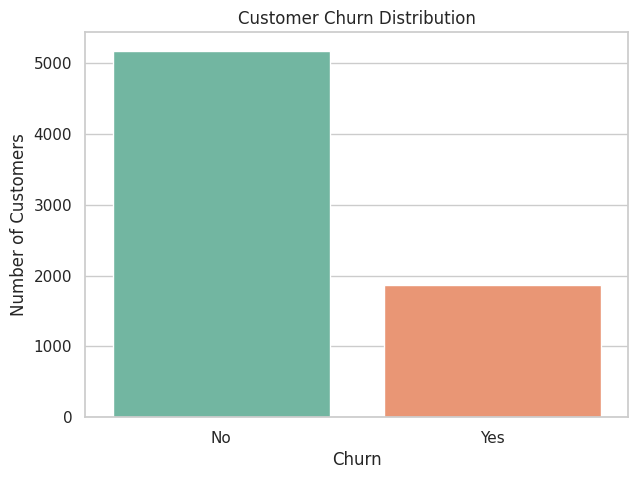


AVERAGE NUMERIC VALUES BY CHURN


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


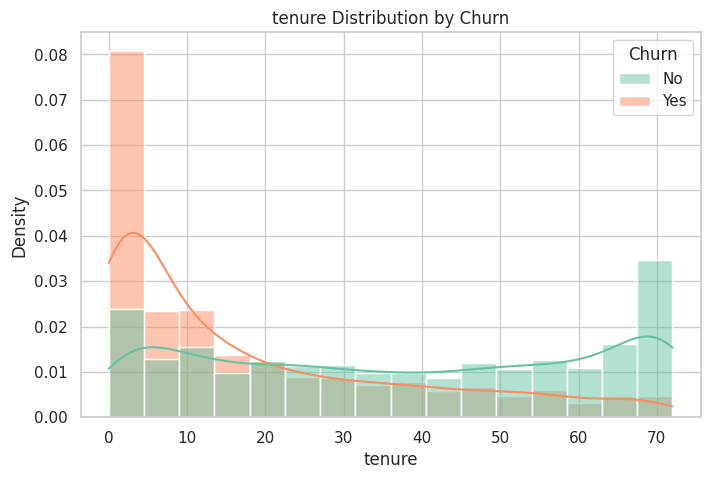

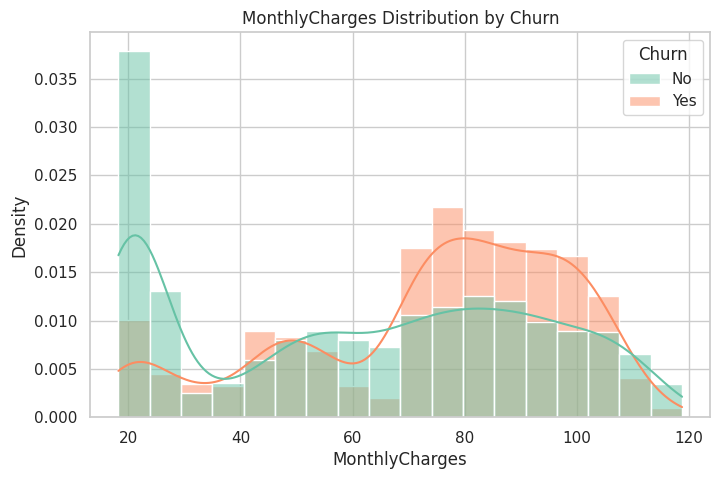

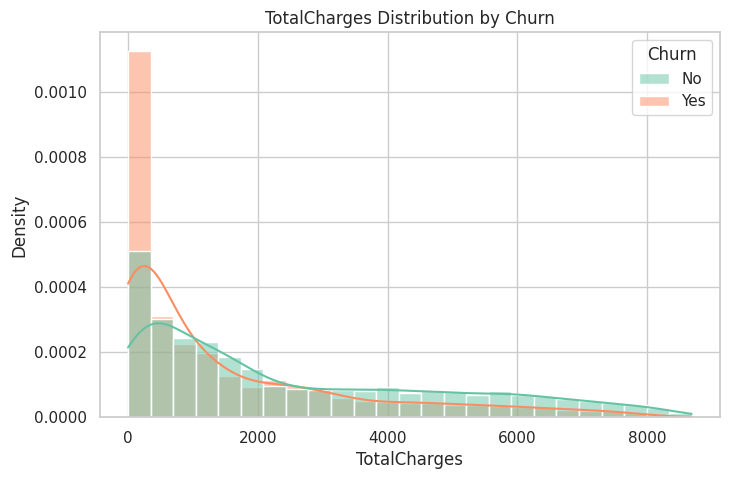


CHURN RATE BY Contract


,Churn Percentage
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


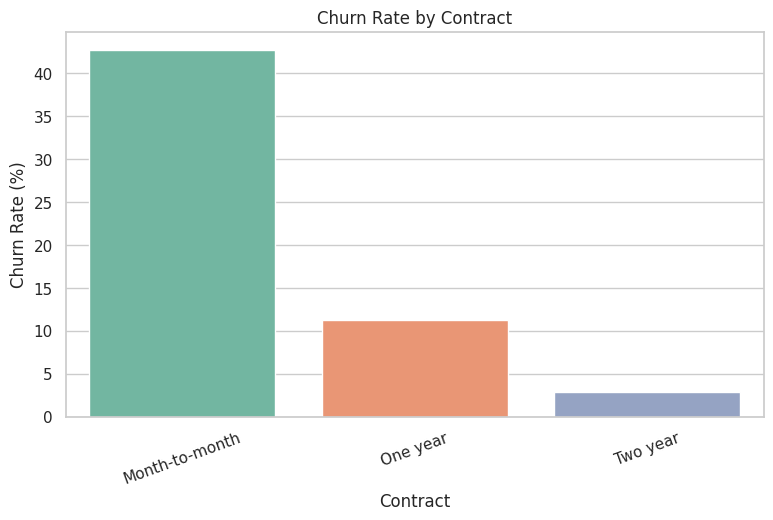


CHURN RATE BY InternetService


,Churn Percentage
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40


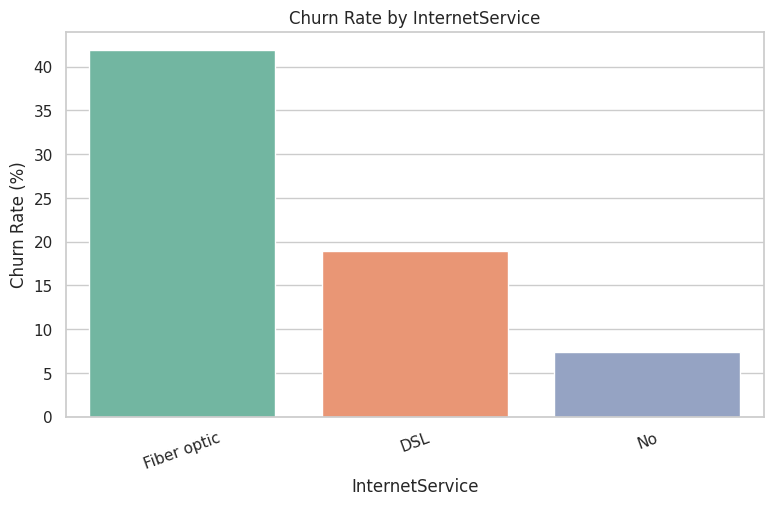


CHURN RATE BY PaymentMethod


,Churn Percentage
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


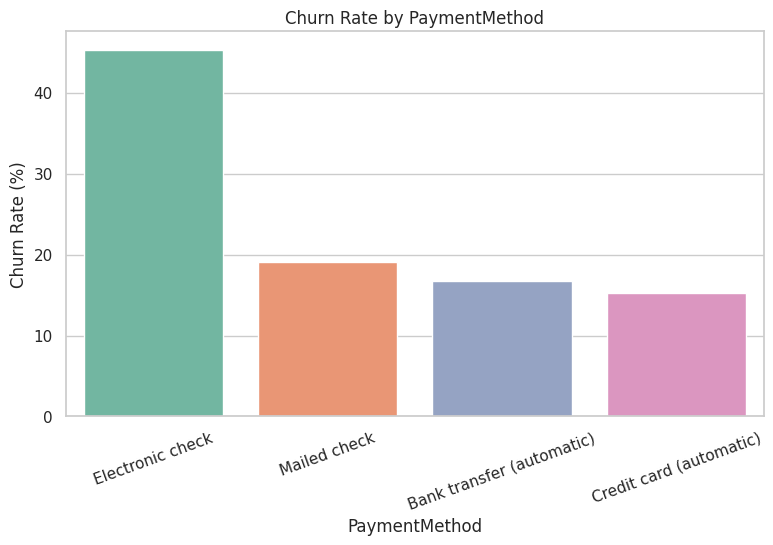


CHURN RATE BY TechSupport


,Churn Percentage
TechSupport,
No,41.64
Yes,15.17
No internet service,7.40


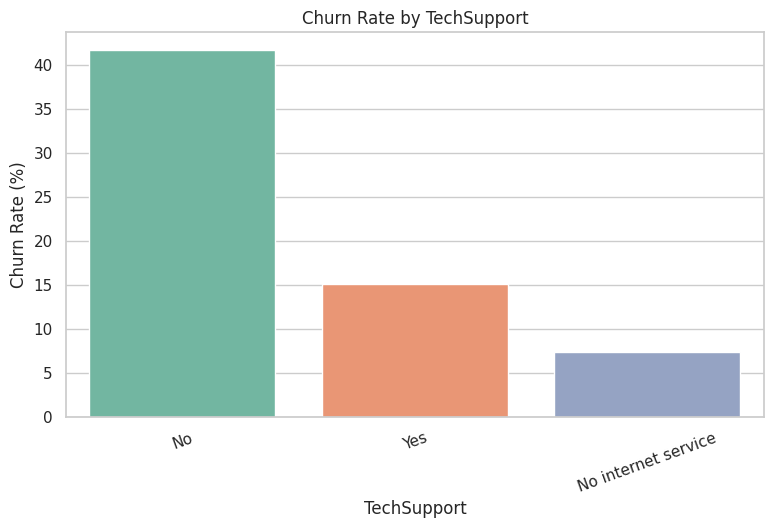


CHURN RATE BY OnlineSecurity


,Churn Percentage
OnlineSecurity,
No,41.77
Yes,14.61
No internet service,7.40


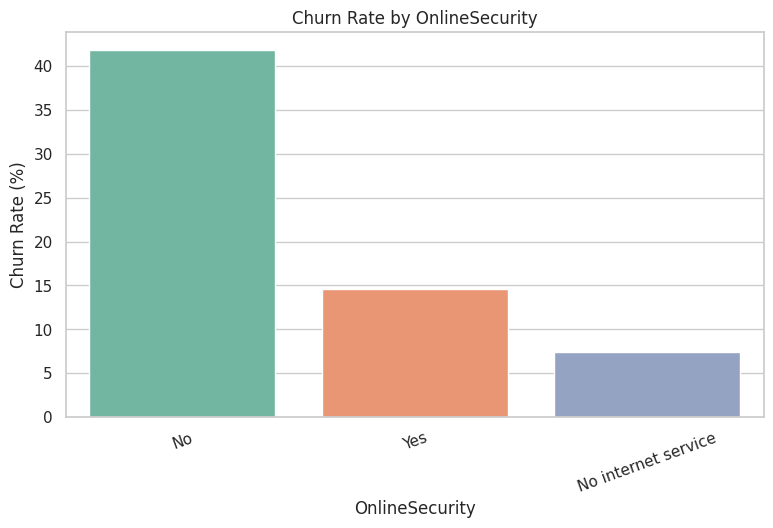


CHURN RATE BY SeniorCitizen


,Churn Percentage
SeniorCitizen,
Senior Citizen,41.68
Not Senior Citizen,23.61


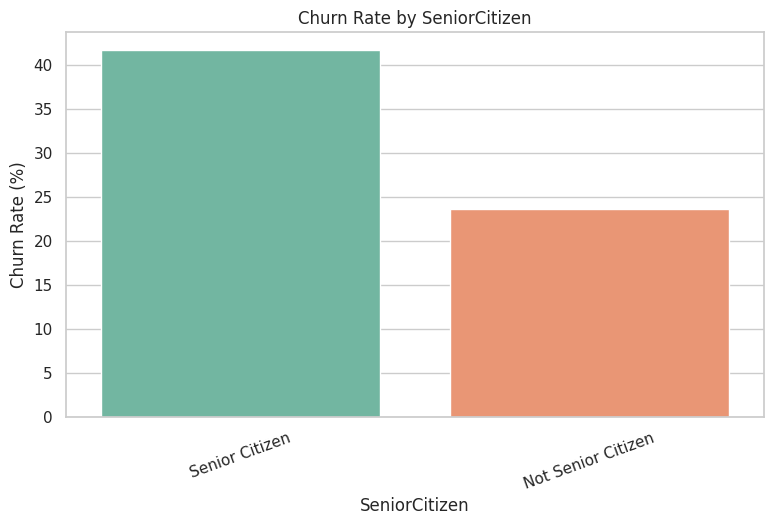


CORRELATION WITH CHURN


,Correlation
tenure,-0.352
MonthlyCharges,0.193
TotalCharges,-0.198
SeniorCitizen,0.151



EDA results saved: /content/drive/MyDrive/ChurnGuard/results/eda_results.json

PLOT FILE VERIFICATION
churn_distribution.png: SAVED
tenure_vs_churn.png: SAVED
monthlycharges_vs_churn.png: SAVED
totalcharges_vs_churn.png: SAVED
contract_vs_churn.png: SAVED
internetservice_vs_churn.png: SAVED
paymentmethod_vs_churn.png: SAVED
techsupport_vs_churn.png: SAVED
onlinesecurity_vs_churn.png: SAVED
seniorcitizen_vs_churn.png: SAVED

EDA COMPLETED SUCCESSFULLY!


In [ ]:


PLOTS_DIR = os.path.join(BASE_DIR, "plots")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")


counts = clean_df["Churn"].value_counts()
percentages = clean_df["Churn"].value_counts(normalize=True) * 100

churn_distribution = pd.DataFrame({
    "Customers": counts,
    "Percentage": percentages.round(2)
})

print("CUSTOMER CHURN DISTRIBUTION")
display(churn_distribution)

imbalance_ratio = counts["No"] / counts["Yes"]
print(f"Imbalance Ratio (No : Yes): {imbalance_ratio:.2f} : 1")

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=clean_df, x="Churn", hue="Churn",
              palette="Set2", legend=False, ax=ax)
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")

fig.savefig(os.path.join(PLOTS_DIR, "churn_distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

print("\nAVERAGE NUMERIC VALUES BY CHURN")
numeric_summary = clean_df.groupby("Churn")[numeric_cols].mean().round(2)
display(numeric_summary)

for col in numeric_cols:

    fig, ax = plt.subplots(figsize=(8, 5))

    sns.histplot(
        data=clean_df,
        x=col,
        hue="Churn",
        kde=True,
        stat="density",
        common_norm=False,
        palette="Set2",
        ax=ax
    )

    ax.set_title(f"{col} Distribution by Churn")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")

    fig.savefig(
        os.path.join(PLOTS_DIR, f"{col.lower()}_vs_churn.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


categorical_cols = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "SeniorCitizen"
]

churn_rates = {}

for col in categorical_cols:

    temp = clean_df.copy()

    if col == "SeniorCitizen":
        temp[col] = temp[col].map({
            0: "Not Senior Citizen",
            1: "Senior Citizen"
        })

    rate = (
        temp.groupby(col, observed=False)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
        .round(2)
    )

    churn_rates[col] = rate.to_dict()

    print(f"\nCHURN RATE BY {col}")
    display(rate.to_frame("Churn Percentage"))

    fig, ax = plt.subplots(figsize=(9, 5))

    sns.barplot(
        x=rate.index,
        y=rate.values,
        hue=rate.index,
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Churn Rate (%)")
    ax.tick_params(axis="x", rotation=20)

    fig.savefig(
        os.path.join(PLOTS_DIR, f"{col.lower()}_vs_churn.png"),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


corr_df = clean_df.copy()
corr_df["ChurnFlag"] = (corr_df["Churn"] == "Yes").astype(int)

correlation = (
    corr_df[
        ["tenure", "MonthlyCharges", "TotalCharges",
         "SeniorCitizen", "ChurnFlag"]
    ]
    .corr()["ChurnFlag"]
    .drop("ChurnFlag")
    .round(3)
)

print("\nCORRELATION WITH CHURN")
display(correlation.to_frame("Correlation"))


eda_results = {
    "total_customers": int(len(clean_df)),
    "churned_customers": int(counts["Yes"]),
    "retained_customers": int(counts["No"]),
    "churn_percentage": float(percentages["Yes"].round(2)),
    "retained_percentage": float(percentages["No"].round(2)),
    "imbalance_ratio": round(float(imbalance_ratio), 2),
    "numeric_average_by_churn": numeric_summary.to_dict(),
    "churn_rates_by_category": churn_rates,
    "correlation_with_churn": correlation.to_dict()
}

eda_path = os.path.join(RESULTS_DIR, "eda_results.json")

with open(eda_path, "w") as f:
    json.dump(eda_results, f, indent=4)

print("\nEDA results saved:", eda_path)


expected_plots = [
    "churn_distribution.png",
    "tenure_vs_churn.png",
    "monthlycharges_vs_churn.png",
    "totalcharges_vs_churn.png",
    "contract_vs_churn.png",
    "internetservice_vs_churn.png",
    "paymentmethod_vs_churn.png",
    "techsupport_vs_churn.png",
    "onlinesecurity_vs_churn.png",
    "seniorcitizen_vs_churn.png"
]

print("\nPLOT FILE VERIFICATION")

for filename in expected_plots:
    path = os.path.join(PLOTS_DIR, filename)
    print(
        f"{filename}:",
        "SAVED" if os.path.exists(path) else "MISSING"
    )

print("\nEDA COMPLETED SUCCESSFULLY!")

SPLITTING

In [ ]:


from sklearn.model_selection import train_test_split


CLEAN_PATH = os.path.join(
    BASE_DIR, "data", "cleaned_telco.csv"
)

clean_df = pd.read_csv(CLEAN_PATH)

print("Dataset Shape:", clean_df.shape)
print("Missing Values:", clean_df.isnull().sum().sum())
print("Duplicate Customer IDs:", clean_df["customerID"].duplicated().sum())

customer_ids = clean_df["customerID"].copy()

X = clean_df.drop(
    columns=["customerID", "Churn"]
)

y = clean_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

assert y.notna().all(), "Target encoding mein unexpected values hain."

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts().rename(index={
    0: "No",
    1: "Yes"
}))

X_train, X_test, y_train, y_test, id_train, id_test = (
    train_test_split(
        X,
        y,
        customer_ids,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("\nTRAINING DATA")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Churn distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTESTING DATA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Churn distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))


assert len(set(id_train).intersection(set(id_test))) == 0

assert set(X_train.columns) == set(X_test.columns)

assert "customerID" not in X_train.columns
assert "Churn" not in X_train.columns

print("\nNo customer ID overlap.")
print("CustomerID excluded from model features.")
print("Train-test split verification passed.")


SPLIT_DIR = os.path.join(BASE_DIR, "checkpoints")
os.makedirs(SPLIT_DIR, exist_ok=True)

split_data = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "id_train": id_train,
    "id_test": id_test,
    "random_state": 42,
    "test_size": 0.20
}

SPLIT_PATH = os.path.join(
    SPLIT_DIR, "train_test_split.joblib"
)

joblib.dump(split_data, SPLIT_PATH)


split_summary = {
    "original_rows": int(len(clean_df)),
    "training_rows": int(len(X_train)),
    "testing_rows": int(len(X_test)),
    "training_churn_percentage": round(
        float(y_train.mean() * 100), 2
    ),
    "testing_churn_percentage": round(
        float(y_test.mean() * 100), 2
    ),
    "test_size": 0.20,
    "random_state": 42,
    "stratified": True,
    "customerID_excluded_from_features": True,
    "customer_id_overlap": 0
}

SUMMARY_PATH = os.path.join(
    BASE_DIR, "results", "split_summary.json"
)

with open(SUMMARY_PATH, "w") as f:
    json.dump(split_summary, f, indent=4)

print("\nSplit saved successfully!")
print("Checkpoint:", SPLIT_PATH)
print("Summary:", SUMMARY_PATH)

Dataset Shape: (7043, 21)
Missing Values: 0
Duplicate Customer IDs: 0

Feature Shape: (7043, 19)
Target Shape: (7043,)

Target Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

TRAINING DATA
X_train: (5634, 19)
y_train: (5634,)
Churn distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

TESTING DATA
X_test: (1409, 19)
y_test: (1409,)
Churn distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

No customer ID overlap.
CustomerID excluded from model features.
Train-test split verification passed.

Split saved successfully!
Checkpoint: /content/drive/MyDrive/ChurnGuard/checkpoints/train_test_split.joblib
Summary: /content/drive/MyDrive/ChurnGuard/results/split_summary.json


PRPROCESSING

In [ ]:


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


SPLIT_PATH = os.path.join(
    BASE_DIR, "checkpoints", "train_test_split.joblib"
)

split_data = joblib.load(SPLIT_PATH)

X_train = split_data["X_train"]
X_test = split_data["X_test"]
y_train = split_data["y_train"]
y_test = split_data["y_test"]

print("Saved split loaded successfully.")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numeric_features))
print("Total Categorical Features:", len(categorical_features))


numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

assert len(numeric_features) + len(categorical_features) == X_train.shape[1]

assert set(X_train.columns) == set(X_test.columns)

assert "customerID" not in X_train.columns
assert "Churn" not in X_train.columns

print("\nPreprocessing configuration verified.")
print("All 19 features assigned to preprocessing groups.")

MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

PREPROCESSOR_PATH = os.path.join(
    MODEL_DIR, "preprocessor.joblib"
)

joblib.dump(preprocessor, PREPROCESSOR_PATH)

preprocessing_config = {
    "numerical_features": numeric_features,
    "categorical_features": categorical_features,
    "numerical_steps": [
        "SimpleImputer(strategy='median')",
        "StandardScaler()"
    ],
    "categorical_steps": [
        "SimpleImputer(strategy='most_frequent')",
        "OneHotEncoder(handle_unknown='ignore')"
    ],
    "total_input_features": int(X_train.shape[1]),
    "preprocessor_fitted": False,
    "fit_strategy": "Inside each cross-validation training fold",
    "customerID_excluded": True,
    "target_excluded": True
}

CONFIG_PATH = os.path.join(
    RESULTS_DIR, "preprocessing_config.json"
)

with open(CONFIG_PATH, "w") as f:
    json.dump(preprocessing_config, f, indent=4)


print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", X_train.shape[1])

print("\nSaved Files:")
print("Preprocessor:", PREPROCESSOR_PATH)
print("Configuration:", CONFIG_PATH)

assert os.path.exists(PREPROCESSOR_PATH)
assert os.path.exists(CONFIG_PATH)


Saved split loaded successfully.
Training shape: (5634, 19)
Testing shape: (1409, 19)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total Numerical Features: 4
Total Categorical Features: 15

Preprocessing configuration verified.
All 19 features assigned to preprocessing groups.
Numerical features: 4
Categorical features: 15
Total input features: 19

Saved Files:
Preprocessor: /content/drive/MyDrive/ChurnGuard/models/preprocessor.joblib
Configuration: /content/drive/MyDrive/ChurnGuard/results/preprocessing_config.json


SOMENTIC USE FOR BALANCING

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.linear_model import LogisticRegression


SPLIT_PATH = os.path.join(
    BASE_DIR, "checkpoints", "train_test_split.joblib"
)

split_data = joblib.load(SPLIT_PATH)

X_train = split_data["X_train"].copy()
X_test = split_data["X_test"].copy()
y_train = split_data["y_train"].copy()
y_test = split_data["y_test"].copy()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

n_numeric = len(numeric_features)
n_categorical = len(categorical_features)


categorical_indices = list(
    range(n_numeric, n_numeric + n_categorical)
)

numeric_indices = list(range(n_numeric))

print("\nNumerical features:", n_numeric)
print("Categorical features:", n_categorical)
print("Categorical positions for SMOTENC:", categorical_indices)

numeric_transformer_smotenc = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_smotenc = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
        dtype=np.float64
    ))
])


pre_smote = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_smotenc, numeric_features),
        ("cat", categorical_transformer_smotenc, categorical_features)
    ],
    remainder="drop",
    sparse_threshold=0
)

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

post_smote = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_indices),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_indices)
    ],
    remainder="drop"
)

def build_smotenc_pipeline(classifier):

    pipeline = ImbPipeline(steps=[
        ("pre_smote", pre_smote),
        ("smotenc", SMOTENC(
            categorical_features=categorical_indices,
            sampling_strategy="auto",
            random_state=42,
            k_neighbors=5
        )),
        ("post_smote", post_smote),
        ("classifier", classifier)
    ])

    return pipeline

smotenc_logistic_template = build_smotenc_pipeline(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)


assert len(numeric_features) == 4
assert len(categorical_features) == 15

assert len(categorical_indices) == 15
assert len(numeric_indices) == 4

assert "customerID" not in X_train.columns
assert "Churn" not in X_train.columns

assert smotenc_logistic_template.steps[1][0] == "smotenc"

print("Numerical features:", numeric_features)
print("Categorical feature count:", len(categorical_features))
print("SMOTENC categorical positions:", categorical_indices)
print("Pipeline stages:", [
    name for name, _ in smotenc_logistic_template.steps
])

CONFIG_DIR = os.path.join(BASE_DIR, "results")
MODEL_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(CONFIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

smotenc_config = {
    "method": "SMOTENC",
    "sampling_strategy": "auto",
    "random_state": 42,
    "k_neighbors": 5,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "numeric_feature_positions": numeric_indices,
    "categorical_feature_positions": categorical_indices,
    "initial_categorical_encoding": "OrdinalEncoder",
    "final_categorical_encoding": "OneHotEncoder",
    "resampling_location": "Inside each training fold only",
    "validation_resampling": False,
    "test_resampling": False
}

CONFIG_PATH = os.path.join(
    CONFIG_DIR, "smotenc_config.json"
)

with open(CONFIG_PATH, "w") as f:
    json.dump(smotenc_config, f, indent=4)

TEMPLATE_PATH = os.path.join(
    MODEL_DIR, "smotenc_logistic_template.joblib"
)

joblib.dump(smotenc_logistic_template, TEMPLATE_PATH)

assert os.path.exists(CONFIG_PATH)
assert os.path.exists(TEMPLATE_PATH)

print("\nSaved configuration:", CONFIG_PATH)
print("Saved pipeline template:", TEMPLATE_PATH)


Training data: (5634, 19)
Testing data: (1409, 19)

Numerical features: 4
Categorical features: 15
Categorical positions for SMOTENC: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 15
SMOTENC categorical positions: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Pipeline stages: ['pre_smote', 'smotenc', 'post_smote', 'classifier']

Saved configuration: /content/drive/MyDrive/ChurnGuard/results/smotenc_config.json
Saved pipeline template: /content/drive/MyDrive/ChurnGuard/models/smotenc_logistic_template.joblib


In [ ]:

import sklearn
import imblearn
import xgboost

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.model_selection import StratifiedKFold

from xgboost import XGBClassifier

SPLIT_PATH = os.path.join(
    BASE_DIR, "checkpoints", "train_test_split.joblib"
)

split_data = joblib.load(SPLIT_PATH)

X_train = split_data["X_train"]
X_test = split_data["X_test"]
y_train = split_data["y_train"]
y_test = split_data["y_test"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


CV_SPLITS = 3
RANDOM_STATE = 42

cv = StratifiedKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("\nCross-validation:")
print("Number of folds:", CV_SPLITS)
print("Strategy: StratifiedKFold")


negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

scale_pos_weight = negative_count / positive_count

print("\nTraining class counts:")
print("No churn:", negative_count)
print("Churn:", positive_count)
print("Class ratio:", round(scale_pos_weight, 3))

def build_class_weight_models():

    models = {}

    models["Logistic_Regression_Weighted"] = (
        SklearnPipeline(steps=[
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=RANDOM_STATE
            ))
        ])
    )

    models["Random_Forest_Weighted"] = (
        SklearnPipeline(steps=[
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])
    )
    models["XGBoost_Weighted"] = (
        SklearnPipeline(steps=[
            ("preprocessor", preprocessor),
            ("classifier", XGBClassifier(
                n_estimators=200,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=scale_pos_weight,
                eval_metric="logloss",
                random_state=RANDOM_STATE,
                n_jobs=-1,
                verbosity=0
            ))
        ])
    )

    return models



def build_smotenc_models():

    models = {}

    models["Logistic_Regression_SMOTENC"] = (
        build_smotenc_pipeline(
            LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE
            )
        )
    )

    models["Random_Forest_SMOTENC"] = (
        build_smotenc_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    )

    models["XGBoost_SMOTENC"] = (
        build_smotenc_pipeline(
            XGBClassifier(
                n_estimators=200,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=RANDOM_STATE,
                n_jobs=-1,
                verbosity=0
            )
        )
    )

    return models

baseline_model = DummyClassifier(
    strategy="prior"
)

model_config = {
    "baseline": [
        "Dummy_Classifier"
    ],
    "class_weight_models": [
        "Logistic_Regression_Weighted",
        "Random_Forest_Weighted",
        "XGBoost_Weighted"
    ],
    "smotenc_models": [
        "Logistic_Regression_SMOTENC",
        "Random_Forest_SMOTENC",
        "XGBoost_SMOTENC"
    ],
    "total_experiments": 7,
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": CV_SPLITS,
        "shuffle": True,
        "random_state": RANDOM_STATE
    },
    "primary_metric": "PR-AUC",
    "additional_metrics": [
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "class_weight_xgboost_scale_pos_weight": round(
        float(scale_pos_weight), 4
    ),
    "smote_strategy": "SMOTENC inside training folds only",
    "test_set_used_for_model_selection": False,
    "random_state": RANDOM_STATE
}

weighted_models = build_class_weight_models()
smotenc_models = build_smotenc_models()

all_model_names = (
    list(weighted_models.keys()) +
    list(smotenc_models.keys())
)

print("\nMODEL EXPERIMENTS")
print("-----------------")
print("Dummy_Classifier")

for name in all_model_names:
    print(name)

assert len(all_model_names) == 6
assert model_config["total_experiments"] == 7

print("\nAll model configurations created successfully.")

CHECKPOINT_DIR = os.path.join(
    BASE_DIR, "checkpoints", "model_training"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


CONFIG_PATH = os.path.join(
    BASE_DIR, "results", "model_config.json"
)

with open(CONFIG_PATH, "w") as f:
    json.dump(model_config, f, indent=4)

TEMPLATE_PATH = os.path.join(
    BASE_DIR, "models", "model_templates.joblib"
)

joblib.dump({
    "baseline": baseline_model,
    "weighted_models": weighted_models,
    "smotenc_models": smotenc_models
}, TEMPLATE_PATH)


environment_info = {
    "sklearn_version": sklearn.__version__,
    "imbalanced_learn_version": imblearn.__version__,
    "xgboost_version": xgboost.__version__,
    "numpy_version": np.__version__
}

ENV_PATH = os.path.join(
    BASE_DIR, "results", "environment_info.json"
)

with open(ENV_PATH, "w") as f:
    json.dump(environment_info, f, indent=4)

assert os.path.exists(CONFIG_PATH)
assert os.path.exists(TEMPLATE_PATH)
assert os.path.exists(ENV_PATH)

print("\nSAVED FILES")
print("Model config:", CONFIG_PATH)
print("Model templates:", TEMPLATE_PATH)
print("Environment:", ENV_PATH)



Training data: (5634, 19)
Testing data: (1409, 19)

Cross-validation:
Number of folds: 3
Strategy: StratifiedKFold

Training class counts:
No churn: 4139
Churn: 1495
Class ratio: 2.769

MODEL EXPERIMENTS
-----------------
Dummy_Classifier
Logistic_Regression_Weighted
Random_Forest_Weighted
XGBoost_Weighted
Logistic_Regression_SMOTENC
Random_Forest_SMOTENC
XGBoost_SMOTENC

All model configurations created successfully.

SAVED FILES
Model config: /content/drive/MyDrive/ChurnGuard/results/model_config.json
Model templates: /content/drive/MyDrive/ChurnGuard/models/model_templates.joblib
Environment: /content/drive/MyDrive/ChurnGuard/results/environment_info.json


TRAINING

In [ ]:
import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

BASE_DIR = "/content/drive/MyDrive/ChurnGuard"
MODEL_DIR = os.path.join(BASE_DIR, "models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints", "model_training")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

N_SPLITS = 5
RANDOM_STATE = 42
CONFIG_VERSION = f"churnguard_cv_v1_k{N_SPLITS}"
METRIC_COLUMNS = ["PR_AUC", "Precision", "Recall", "F1", "ROC_AUC"]

split_data = joblib.load(os.path.join(BASE_DIR, "checkpoints", "train_test_split.joblib"))
templates = joblib.load(os.path.join(MODEL_DIR, "model_templates.joblib"))

X_train = split_data["X_train"]
y_train = pd.Series(split_data["y_train"], index=X_train.index).astype(int)

model_templates = {
    "Dummy_Classifier": templates["baseline"],
    **templates["weighted_models"],
    **templates["smotenc_models"],
}
expected_models = list(model_templates.keys())

if len(expected_models) != 7:
    raise ValueError("Expected 7 models in the saved templates.")

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train))


def positive_probability(model, X):
    return model.predict_proba(X)[:, 1]


def score(y_true, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        "PR_AUC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
    }


def checkpoint_path(model_name, fold_number):
    return os.path.join(CHECKPOINT_DIR, f"{model_name}_fold_{fold_number}.joblib")


def is_valid(item, model_name, fold_number, val_labels):
    return (
        isinstance(item, dict)
        and item.get("config_version") == CONFIG_VERSION
        and item.get("model_name") == model_name
        and item.get("fold") == fold_number
        and np.array_equal(item.get("validation_indices"), val_labels)
    )


def load_or_train(model_name, fold_number, train_idx, val_idx):
    path = checkpoint_path(model_name, fold_number)
    val_labels = X_train.index[val_idx].to_numpy()

    if os.path.exists(path):
        try:
            item = joblib.load(path)
            if is_valid(item, model_name, fold_number, val_labels):
                return item
        except Exception:
            pass

    model = clone(model_templates[model_name])
    model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    item = {
        "config_version": CONFIG_VERSION,
        "model_name": model_name,
        "fold": fold_number,
        "validation_indices": val_labels,
        "y_true": y_train.iloc[val_idx].to_numpy(),
        "y_prob": positive_probability(model, X_train.iloc[val_idx]),
    }
    joblib.dump(item, path, compress=3)
    return item


fold_rows = []
failed = []

for model_name in expected_models:
    for fold_number, (train_idx, val_idx) in enumerate(folds, 1):
        try:
            item = load_or_train(model_name, fold_number, train_idx, val_idx)
        except Exception as error:
            failed.append({"model": model_name, "fold": fold_number, "error": str(error)})
            continue

        fold_rows.append({
            "model": model_name,
            "fold": fold_number,
            **score(item["y_true"], item["y_prob"]),
        })

fold_df = pd.DataFrame(fold_rows)

if fold_df.empty:
    raise RuntimeError("No fold results were produced.")

fold_df.to_csv(os.path.join(RESULTS_DIR, "cv_fold_metrics.csv"), index=False)

comparison = fold_df.groupby("model")[METRIC_COLUMNS].agg(["mean", "std"])
comparison.columns = [f"{metric}_{stat}" for metric, stat in comparison.columns]
comparison = (
    comparison.reset_index()
    .sort_values("PR_AUC_mean", ascending=False)
)
comparison.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"), index=False)

print(comparison.round(4).to_string(index=False))

oof_predictions = {}

for model_name in expected_models:
    items = []

    for fold_number, (_, val_idx) in enumerate(folds, 1):
        path = checkpoint_path(model_name, fold_number)
        if not os.path.exists(path):
            break

        item = joblib.load(path)
        if not is_valid(item, model_name, fold_number, X_train.index[val_idx].to_numpy()):
            break

        items.append(item)

    if len(items) != N_SPLITS:
        continue

    oof = pd.DataFrame({
        "customer_index": np.concatenate([i["validation_indices"] for i in items]),
        "y_true": np.concatenate([i["y_true"] for i in items]),
        "y_probability": np.concatenate([i["y_prob"] for i in items]),
    }).sort_values("customer_index").reset_index(drop=True)

    if len(oof) == len(X_train) and oof["customer_index"].is_unique:
        oof_predictions[model_name] = oof

joblib.dump(oof_predictions, os.path.join(RESULTS_DIR, "oof_predictions.joblib"), compress=3)

with open(os.path.join(RESULTS_DIR, "cv_errors.json"), "w") as f:
    json.dump(failed, f, indent=4)

expected_folds = len(expected_models) * N_SPLITS
success = (
    len(fold_df) == expected_folds
    and len(oof_predictions) == len(expected_models)
    and not failed
)

print(
    f"Folds: {len(fold_df)}/{expected_folds} | "
    f"OOF models: {len(oof_predictions)}/{len(expected_models)} | "
    f"Failed: {len(failed)} | "
    f"Status: {'SUCCESS' if success else 'INCOMPLETE'}"
)

                       model  PR_AUC_mean  PR_AUC_std  Precision_mean  Precision_std  Recall_mean  Recall_std  F1_mean  F1_std  ROC_AUC_mean  ROC_AUC_std
            XGBoost_Weighted       0.6690      0.0230          0.5214         0.0162       0.8007      0.0332   0.6314  0.0201        0.8477       0.0125
Logistic_Regression_Weighted       0.6600      0.0218          0.5169         0.0211       0.8013      0.0424   0.6283  0.0259        0.8460       0.0139
             XGBoost_SMOTENC       0.6596      0.0198          0.5478         0.0132       0.7425      0.0254   0.6303  0.0127        0.8449       0.0120
 Logistic_Regression_SMOTENC       0.6500      0.0279          0.5333         0.0186       0.7659      0.0294   0.6285  0.0161        0.8414       0.0139
      Random_Forest_Weighted       0.6101      0.0344          0.6278         0.0307       0.4803      0.0304   0.5440  0.0287        0.8206       0.0134
       Random_Forest_SMOTENC       0.5897      0.0357          0.5690       

XGBoost PROBABILITY  CALIBRATION ANALYSIS

Available OOF models: ['Dummy_Classifier', 'Logistic_Regression_Weighted', 'Random_Forest_Weighted', 'XGBoost_Weighted', 'Logistic_Regression_SMOTENC', 'Random_Forest_SMOTENC', 'XGBoost_SMOTENC']


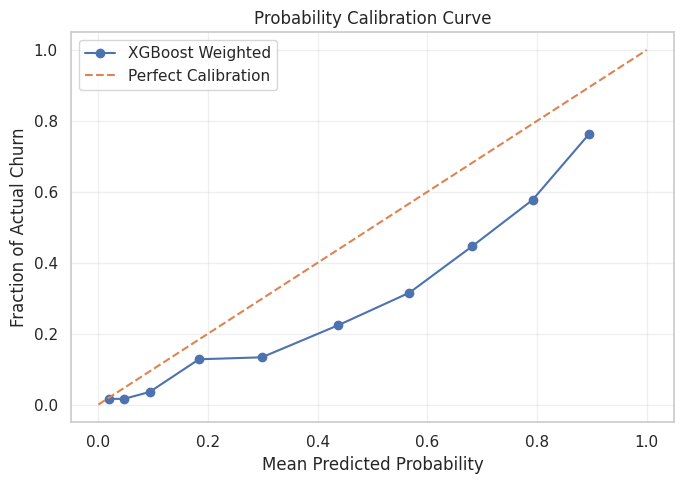

Model       : XGBoost_Weighted
Brier Score : 0.1606
Samples     : 5634
Saved       : calibration_curve.png
Saved       : calibration_analysis.json


In [ ]:


from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

BASE_DIR = "/content/drive/MyDrive/ChurnGuard"
MODEL_NAME = "XGBoost_Weighted"

oof_path = f"{BASE_DIR}/results/oof_predictions.joblib"
oof_data = joblib.load(oof_path)

print("Available OOF models:", list(oof_data.keys()))

predictions = oof_data[MODEL_NAME]

if isinstance(predictions, pd.DataFrame):
    y_true = predictions["y_true"].to_numpy()
    y_prob = predictions["y_probability"].to_numpy()
else:
    raise TypeError("Unexpected OOF prediction format. Please inspect predictions.")

valid = np.isfinite(y_prob)

y_true = y_true[valid]
y_prob = np.clip(y_prob[valid], 0, 1)

brier = brier_score_loss(y_true, y_prob)

fraction_positive, mean_predicted = calibration_curve(
    y_true,
    y_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))
plt.plot(mean_predicted, fraction_positive, marker="o", label="XGBoost Weighted")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Actual Churn")
plt.title("Probability Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plot_path = f"{BASE_DIR}/plots/calibration_curve.png"
plt.savefig(plot_path, dpi=300)
plt.show()

calibration_result = {
    "model": MODEL_NAME,
    "brier_score": float(brier),
    "sample_count": int(len(y_true)),
    "calibration_bins": 10
}

result_path = f"{BASE_DIR}/results/calibration_analysis.json"

with open(result_path, "w") as f:
    json.dump(calibration_result, f, indent=4)


print(f"Model       : {MODEL_NAME}")
print(f"Brier Score : {brier:.4f}")
print(f"Samples     : {len(y_true)}")
print(f"Saved       : calibration_curve.png")
print(f"Saved       : calibration_analysis.json")


THRESHOLD TUNING

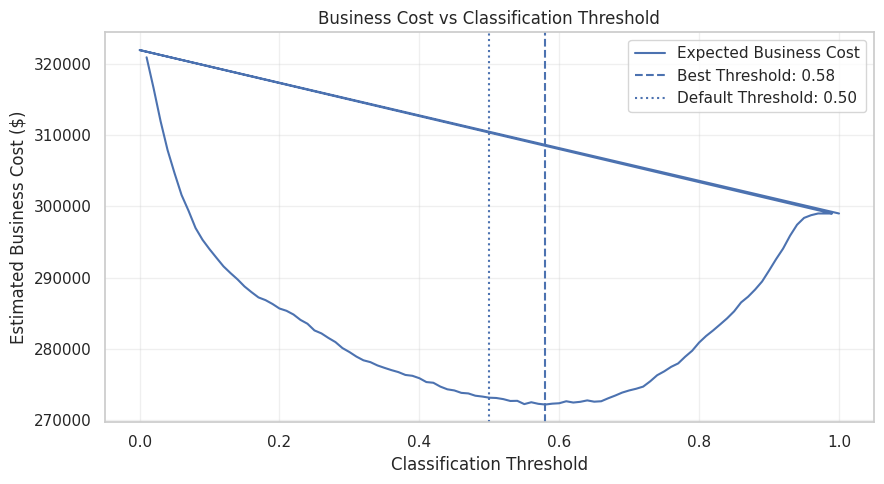

Model                 : XGBoost_Weighted
OOF samples           : 5634
Best threshold        : 0.58
Precision             : 0.5686
Recall                : 0.7237
F1-score              : 0.6368
Targeted customers    : 1903
Baseline business cost: $299,000.00
Optimized business cost: $272,140.00
Estimated savings     : $26,860.00
              Threshold  Precision  Recall      F1  Targeted_Customers  Expected_Cost  Estimated_Savings
Default 0.50       0.50     0.5213  0.8007  0.6315              2296.0       273100.0            25900.0
Optimized          0.58     0.5686  0.7237  0.6368              1903.0       272140.0            26860.0

FILES SAVED
threshold_analysis.csv
selected_threshold.json
threshold_cost_curve.png


In [ ]:

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

BASE_DIR = "/content/drive/MyDrive/ChurnGuard"

OFFER_COST = 20
LOST_CUSTOMER_VALUE = 200
RETENTION_SUCCESS_RATE = 0.30

MODEL_NAME = "XGBoost_Weighted"

oof_data = joblib.load(
    f"{BASE_DIR}/results/oof_predictions.joblib"
)

predictions = oof_data[MODEL_NAME]

if not isinstance(predictions, pd.DataFrame):
    raise TypeError("OOF predictions must be a pandas DataFrame.")

required_columns = {"y_true", "y_probability"}

if not required_columns.issubset(predictions.columns):
    raise ValueError(
        f"Missing columns: {required_columns - set(predictions.columns)}"
    )

data = predictions[["y_true", "y_probability"]].copy()
data = data.replace([np.inf, -np.inf], np.nan).dropna()

y_true = data["y_true"].astype(int).to_numpy()
y_prob = data["y_probability"].astype(float).to_numpy()

if not set(np.unique(y_true)).issubset({0, 1}):
    raise ValueError("Target must contain only 0 and 1.")

if not np.all((y_prob >= 0) & (y_prob <= 1)):
    raise ValueError("Predicted probabilities must be between 0 and 1.")

thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)
thresholds = np.append(thresholds, [0.0, 1.0])

baseline_cost = np.sum(y_true == 1) * LOST_CUSTOMER_VALUE

results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    targeted_customers = tp + fp

    cost_tp = tp * (
        OFFER_COST +
        (1 - RETENTION_SUCCESS_RATE) * LOST_CUSTOMER_VALUE
    )

    cost_fp = fp * OFFER_COST
    cost_fn = fn * LOST_CUSTOMER_VALUE

    total_cost = cost_tp + cost_fp + cost_fn

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "Targeted_Customers": int(targeted_customers),
        "Expected_Cost": float(total_cost),
        "Estimated_Savings": float(baseline_cost - total_cost)
    })

threshold_results = pd.DataFrame(results)

best_row = threshold_results.loc[
    threshold_results["Expected_Cost"].idxmin()
]

best_threshold = float(best_row["Threshold"])

default_row = threshold_results.loc[
    threshold_results["Threshold"] == 0.50
].iloc[0]

os.makedirs(f"{BASE_DIR}/results", exist_ok=True)
os.makedirs(f"{BASE_DIR}/plots", exist_ok=True)

threshold_results.to_csv(
    f"{BASE_DIR}/results/threshold_analysis.csv",
    index=False
)

threshold_config = {
    "model": MODEL_NAME,
    "selected_threshold": best_threshold,
    "offer_cost": OFFER_COST,
    "lost_customer_value": LOST_CUSTOMER_VALUE,
    "retention_success_rate": RETENTION_SUCCESS_RATE,
    "baseline_cost": float(baseline_cost),
    "minimum_expected_cost": float(best_row["Expected_Cost"]),
    "estimated_savings": float(best_row["Estimated_Savings"]),
    "oof_samples": int(len(y_true)),
    "selection_method": "Minimum estimated business cost"
}

with open(
    f"{BASE_DIR}/results/selected_threshold.json", "w"
) as f:
    json.dump(threshold_config, f, indent=4)

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Expected_Cost"],
    label="Expected Business Cost"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Threshold: {best_threshold:.2f}"
)

plt.axvline(
    0.50,
    linestyle=":",
    label="Default Threshold: 0.50"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Estimated Business Cost ($)")
plt.title("Business Cost vs Classification Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{BASE_DIR}/plots/threshold_cost_curve.png",
    dpi=300
)

plt.show()

print(f"Model                 : {MODEL_NAME}")
print(f"OOF samples           : {len(y_true)}")
print(f"Best threshold        : {best_threshold:.2f}")
print(f"Precision             : {best_row['Precision']:.4f}")
print(f"Recall                : {best_row['Recall']:.4f}")
print(f"F1-score              : {best_row['F1']:.4f}")
print(f"Targeted customers    : {int(best_row['Targeted_Customers'])}")
print(f"Baseline business cost: ${baseline_cost:,.2f}")
print(f"Optimized business cost: ${best_row['Expected_Cost']:,.2f}")
print(f"Estimated savings     : ${best_row['Estimated_Savings']:,.2f}")


comparison = pd.DataFrame(
    [default_row, best_row],
    index=["Default 0.50", "Optimized"]
)

print(
    comparison[
        ["Threshold", "Precision", "Recall", "F1",
         "Targeted_Customers", "Expected_Cost", "Estimated_Savings"]
    ].round(4).to_string()
)

print("\nFILES SAVED")
print("threshold_analysis.csv")
print("selected_threshold.json")
print("threshold_cost_curve.png")


FINAL MODEL EVALUATION

Training final XGBoost model...


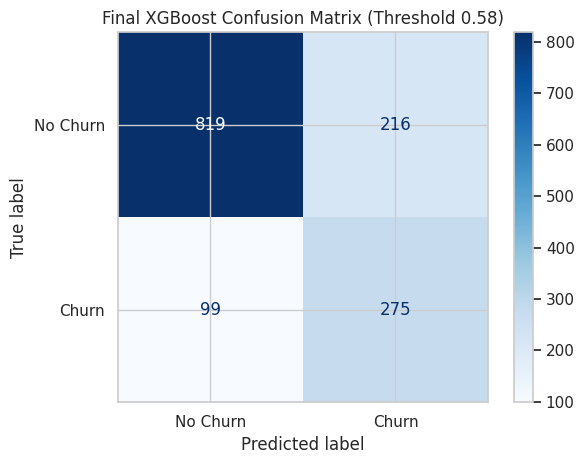


FINAL TEST RESULTS
-------------------
Threshold       : 0.58
Accuracy        : 0.7764
Precision       : 0.5601
Recall          : 0.7353
F1-score        : 0.6358
ROC-AUC         : 0.8483
PR-AUC          : 0.6710
Brier Score     : 0.1612
Targeted customers : 491
Estimated cost     : $68,120.00
Estimated savings  : $6,680.00

SAVED
final_model.joblib
final_test_metrics.json
final_test_metrics.csv
final_test_confusion_matrix.png


In [ ]:

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

BASE_DIR = "/content/drive/MyDrive/ChurnGuard"

split_data = joblib.load(
    f"{BASE_DIR}/checkpoints/train_test_split.joblib"
)

templates = joblib.load(
    f"{BASE_DIR}/models/model_templates.joblib"
)

with open(
    f"{BASE_DIR}/results/selected_threshold.json"
) as f:
    threshold_config = json.load(f)

X_train = split_data["X_train"]
y_train = split_data["y_train"]
X_test = split_data["X_test"]
y_test = split_data["y_test"]

THRESHOLD = threshold_config["selected_threshold"]

final_model = templates["weighted_models"]["XGBoost_Weighted"]

print("Training final XGBoost model...")
final_model.fit(X_train, y_train)

probabilities = final_model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, predictions, labels=[0, 1]
).ravel()

OFFER_COST = 20
LOST_VALUE = 200
SUCCESS_RATE = 0.30

baseline_cost = (tp + fn) * LOST_VALUE

estimated_cost = (
    tp * (OFFER_COST + (1 - SUCCESS_RATE) * LOST_VALUE)
    + fp * OFFER_COST
    + fn * LOST_VALUE
)

metrics = {
    "model": "XGBoost_Weighted",
    "threshold": float(THRESHOLD),
    "accuracy": float(accuracy_score(y_test, predictions)),
    "precision": float(precision_score(y_test, predictions, zero_division=0)),
    "recall": float(recall_score(y_test, predictions, zero_division=0)),
    "f1_score": float(f1_score(y_test, predictions, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, probabilities)),
    "pr_auc": float(average_precision_score(y_test, probabilities)),
    "brier_score": float(np.mean((probabilities - y_test.to_numpy()) ** 2)),
    "true_positive": int(tp),
    "false_positive": int(fp),
    "true_negative": int(tn),
    "false_negative": int(fn),
    "targeted_customers": int(tp + fp),
    "baseline_cost": float(baseline_cost),
    "estimated_cost": float(estimated_cost),
    "estimated_savings": float(baseline_cost - estimated_cost)
}

os.makedirs(f"{BASE_DIR}/models", exist_ok=True)
os.makedirs(f"{BASE_DIR}/results", exist_ok=True)
os.makedirs(f"{BASE_DIR}/plots", exist_ok=True)

joblib.dump(
    final_model,
    f"{BASE_DIR}/models/final_model.joblib"
)

with open(
    f"{BASE_DIR}/results/final_test_metrics.json", "w"
) as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame([metrics]).to_csv(
    f"{BASE_DIR}/results/final_test_metrics.csv",
    index=False
)

display = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, predictions),
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues", values_format="d")
plt.title(f"Final XGBoost Confusion Matrix (Threshold {THRESHOLD:.2f})")
plt.tight_layout()
plt.savefig(
    f"{BASE_DIR}/plots/final_test_confusion_matrix.png",
    dpi=300
)
plt.show()

print("\nFINAL TEST RESULTS")
print("-------------------")
print(f"Threshold       : {THRESHOLD:.2f}")
print(f"Accuracy        : {metrics['accuracy']:.4f}")
print(f"Precision       : {metrics['precision']:.4f}")
print(f"Recall          : {metrics['recall']:.4f}")
print(f"F1-score        : {metrics['f1_score']:.4f}")
print(f"ROC-AUC         : {metrics['roc_auc']:.4f}")
print(f"PR-AUC          : {metrics['pr_auc']:.4f}")
print(f"Brier Score     : {metrics['brier_score']:.4f}")


print(f"Targeted customers : {tp + fp}")
print(f"Estimated cost     : ${estimated_cost:,.2f}")
print(f"Estimated savings  : ${baseline_cost - estimated_cost:,.2f}")

print("\nSAVED")
print("final_model.joblib")
print("final_test_metrics.json")
print("final_test_metrics.csv")
print("final_test_confusion_matrix.png")


Global & local explanations with SHAP

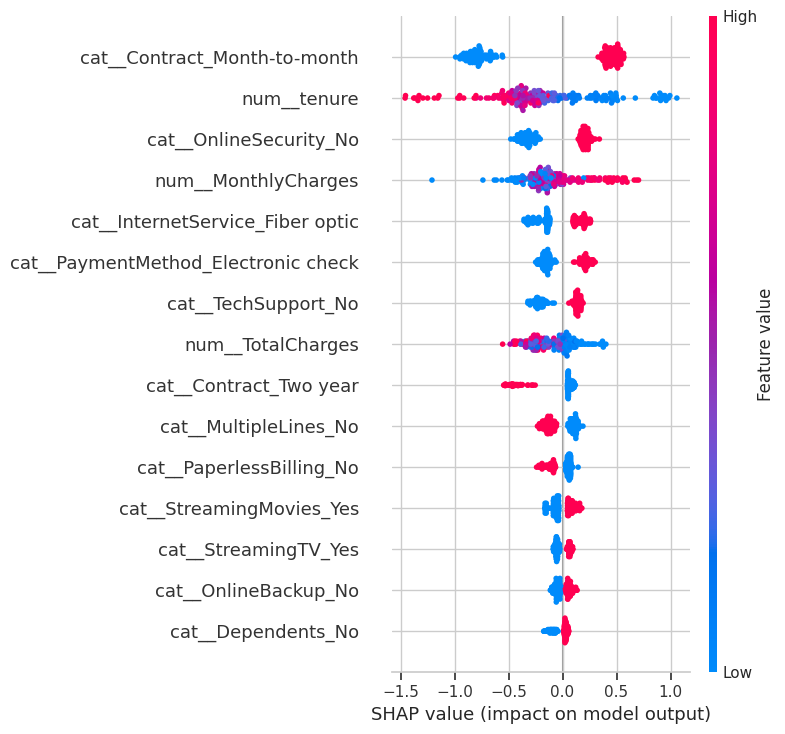

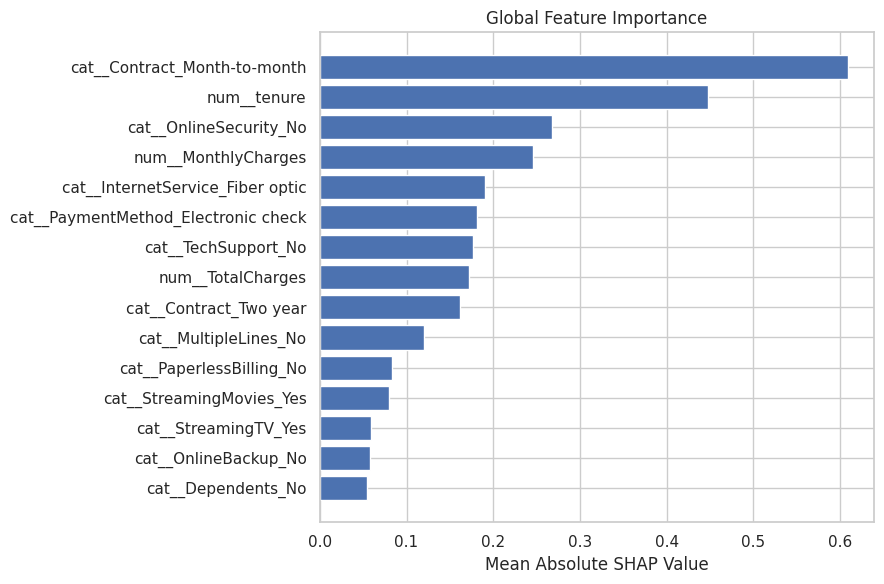

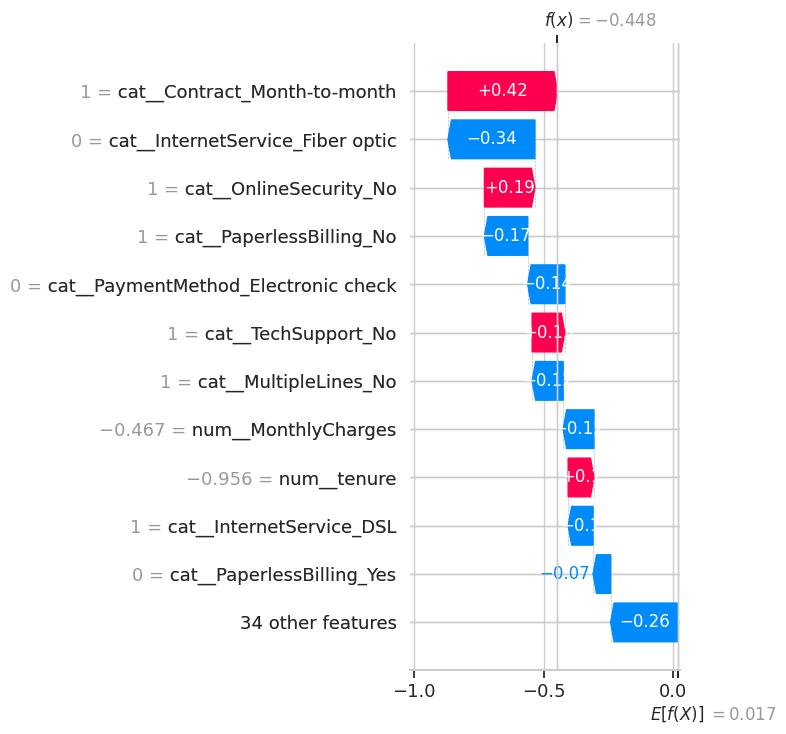


SHAP ANALYSIS COMPLETE
-----------------------
Model             : XGBoost Weighted
Explained samples : 200
Customer index    : 5902
Churn probability : 38.99%
Prediction        : No Churn

TOP 10 GLOBAL FEATURES
                            Feature  Mean_Absolute_SHAP
       cat__Contract_Month-to-month            0.608517
                        num__tenure            0.447135
             cat__OnlineSecurity_No            0.267419
                num__MonthlyCharges            0.245425
   cat__InternetService_Fiber optic            0.189973
cat__PaymentMethod_Electronic check            0.181321
                cat__TechSupport_No            0.176083
                  num__TotalCharges            0.171609
             cat__Contract_Two year            0.161973
              cat__MultipleLines_No            0.119780

FILES SAVED
shap_global_summary.png
shap_feature_importance.png
shap_local_explanation.png
shap_feature_importance.csv
shap_customer_explanation.csv
shap_summary.json


In [ ]:

!pip -q install shap

import shap

BASE_DIR = "/content/drive/MyDrive/ChurnGuard"

model = joblib.load(
    f"{BASE_DIR}/models/final_model.joblib"
)

split_data = joblib.load(
    f"{BASE_DIR}/checkpoints/train_test_split.joblib"
)

X_test = split_data["X_test"]
y_test = split_data["y_test"]

THRESHOLD = 0.58

sample_size = min(200, len(X_test))
X_sample = X_test.sample(
    n=sample_size,
    random_state=42
)

preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

X_transformed = preprocessor.transform(X_sample)

if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()

X_transformed_df = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X_sample.index
)

explainer = shap.TreeExplainer(classifier)

shap_values = explainer.shap_values(X_transformed_df)

if isinstance(shap_values, list):
    shap_values = shap_values[1]

if len(shap_values.shape) == 3:
    shap_values = shap_values[:, :, 1]

os.makedirs(f"{BASE_DIR}/plots", exist_ok=True)
os.makedirs(f"{BASE_DIR}/results", exist_ok=True)

plt.figure()
shap.summary_plot(
    shap_values,
    X_transformed_df,
    show=False,
    max_display=15
)
plt.tight_layout()
plt.savefig(
    f"{BASE_DIR}/plots/shap_global_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

importance = np.abs(shap_values).mean(axis=0)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": importance
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

importance_df.to_csv(
    f"{BASE_DIR}/results/shap_feature_importance.csv",
    index=False
)

top_features = importance_df.head(15).sort_values(
    "Mean_Absolute_SHAP"
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.title("Global Feature Importance")
plt.tight_layout()
plt.savefig(
    f"{BASE_DIR}/plots/shap_feature_importance.png",
    dpi=300
)
plt.show()

customer_position = 0
customer_index = X_sample.index[customer_position]

local_explanation = shap.Explanation(
    values=shap_values[customer_position],
    base_values=explainer.expected_value,
    data=X_transformed_df.iloc[customer_position].values,
    feature_names=feature_names
)

if isinstance(local_explanation.base_values, np.ndarray):
    if local_explanation.base_values.ndim > 0:
        local_explanation.base_values = float(
            np.asarray(local_explanation.base_values).flatten()[-1]
        )
else:
    local_explanation.base_values = float(
        local_explanation.base_values
    )

plt.figure()
shap.plots.waterfall(
    local_explanation,
    max_display=12,
    show=False
)
plt.tight_layout()
plt.savefig(
    f"{BASE_DIR}/plots/shap_local_explanation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

customer_probability = float(
    model.predict_proba(X_sample.iloc[[customer_position]])[0, 1]
)

customer_prediction = int(
    customer_probability >= THRESHOLD
)

local_importance = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": shap_values[customer_position]
})

local_importance["Absolute_SHAP"] = (
    local_importance["SHAP_Value"].abs()
)

local_importance = local_importance.sort_values(
    "Absolute_SHAP",
    ascending=False
)

local_importance.head(10).to_csv(
    f"{BASE_DIR}/results/shap_customer_explanation.csv",
    index=False
)

summary = {
    "explainer": "SHAP TreeExplainer",
    "model": "XGBoost_Weighted",
    "sample_size": int(sample_size),
    "explained_customer_index": str(customer_index),
    "churn_probability": customer_probability,
    "selected_threshold": THRESHOLD,
    "prediction": "Churn" if customer_prediction else "No Churn",
    "top_global_features": importance_df.head(10)["Feature"].tolist()
}

with open(
    f"{BASE_DIR}/results/shap_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\nSHAP ANALYSIS COMPLETE")
print("-----------------------")
print("Model             : XGBoost Weighted")
print("Explained samples :", sample_size)
print("Customer index    :", customer_index)
print(f"Churn probability : {customer_probability:.2%}")
print("Prediction        :", "Churn" if customer_prediction else "No Churn")

print("\nTOP 10 GLOBAL FEATURES")
print(importance_df.head(10).to_string(index=False))

print("\nFILES SAVED")
print("shap_global_summary.png")
print("shap_feature_importance.png")
print("shap_local_explanation.png")
print("shap_feature_importance.csv")
print("shap_customer_explanation.csv")
print("shap_summary.json")
